# Experiment 07: Batch size at best learning rate

Card: [exp07_batch_size_best_lr.md](../../experiments/exp07_batch_size_best_lr.md)


In [29]:
import os
import sys

import lightning.pytorch as L
from lightning.pytorch.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp07_batch_size_best_lr"
EMB_DIM = 12  # picked in exp03
THRESHOLD = 0.01
NEW = [(4096, 3e-2)]  # trained here; every other setup is read from REFERENCES
if SMOKE:
    EXPERIMENT = "ashrae-mlp-batch-size-best-lr-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS, WINDOW = 3, 1
    SETUPS = {4096: [1e-2, 3e-2], 8192: [3e-2]}
    # (experiment, session, batch size when the runs don't tag it); None: the latest session
    REFERENCES = [
        ("ashrae-mlp-optimizers-smoke", None, 4096),
        ("ashrae-mlp-optimizers-large-batch-smoke", None, None),
    ]
    TIMING = ("ashrae-mlp-batch-size-smoke", None)
    FIGURE = FIGURE_RATES = None
else:
    EXPERIMENT = "ashrae-mlp-batch-size-best-lr"
    TRAIN = False  # trained in the session below; True trains only runs it lacks
    SESSION = "2026-10-12 20:30:27"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WINDOW = (
        5  # epochs before the best one over which the epoch-to-epoch change is averaged
    )
    # Adam rates per batch size; a size with several keeps the one with the lowest score
    SETUPS = {4096: [1e-2, 3e-2], 8192: [3e-2], 16384: [3e-2]}
    REFERENCES = [
        ("ashrae-mlp-optimizers", "2026-10-12 13:42:10", 4096),  # exp05
        ("ashrae-mlp-optimizers-large-batch", "2026-10-12 19:15:33", None),  # exp06
    ]
    TIMING = ("ashrae-mlp-batch-size", "2026-10-12 15:01:13")  # exp04
    FIGURE = "../../figures/exp07_batch_size_best_lr.png"
    FIGURE_RATES = "../../figures/exp07_batch_size_best_lr_rates.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-batch-size-best-lr', session 2026-10-12 20:30:27


## Training


In [30]:
def at_best(run_id):
    """A run's scores at its best validation epoch and its per-epoch curve; a diverged run scores inf."""
    val = np.array(experiment.history(run_id, "val_rmsle"))
    if not np.isfinite(val).all():
        return {
            "best_epoch": np.nan,
            "val": np.inf,
            "val_clean": np.inf,
            "train": np.inf,
            "change": np.nan,
            "val_curve": val,
        }
    b = int(val.argmin())
    return {
        "best_epoch": b + 1,
        "val": val[b],
        "val_clean": experiment.history(run_id, "val_rmsle_clean")[b],
        "train": experiment.history(run_id, "train_rmsle")[b],
        "change": (
            np.abs(np.diff(val[max(b - WINDOW, 0) : b + 1])).mean() if b else np.nan
        ),
        "val_curve": val,
    }


def session_runs(experiment_name, session):
    """Finished runs of one session of another notebook (the latest one if `session` is None)."""
    runs = mlflow.search_runs(
        experiment_names=[experiment_name],
        filter_string="attributes.status = 'FINISHED'",
    )
    runs = runs.rename(columns=lambda c: c.removeprefix("tags."))
    return runs[runs.session == (session or runs.session.max())]


def reference_runs():
    """Adam runs of mlp_4out_emb from REFERENCES, at every rate they tried."""
    found = []
    for name, session, batch_size in REFERENCES:
        runs = session_runs(name, session)
        runs = runs[(runs.model == "mlp_4out_emb") & (runs.optimizer == "Adam")]
        if batch_size is not None:
            runs = runs.assign(batch_size=str(batch_size))
        found.append(runs)
    return pd.concat(found)


def scores():
    runs = experiment.runs().rename(columns=lambda c: c.removeprefix("tags."))
    runs = runs[runs.status == "FINISHED"]  # an interrupted run is retrained
    runs = pd.concat([runs, reference_runs()])[
        ["run_id", "batch_size", "lr", "fold"]
    ].assign(
        batch_size=lambda r: r.batch_size.astype(int), lr=lambda r: r.lr.astype(float)
    )
    runs = runs[runs.fold.isin(FOLD_NAMES) & runs.batch_size.isin(SETUPS)].reset_index(
        drop=True
    )
    scored = pd.DataFrame([at_best(r) for r in runs.run_id], index=runs.index)
    return pd.concat([runs, scored], axis=1)


def epoch_seconds():
    """Mean seconds per training epoch of each batch size, from TIMING; epoch time doesn't depend on Adam's rate."""
    runs = session_runs(*TIMING)
    seconds = [np.mean(experiment.history(r, "epoch_seconds")) for r in runs.run_id]
    return (
        pd.Series(seconds, index=runs.batch_size.astype(int).values)
        .groupby(level=0)
        .mean()
    )


class CleanRMSLE(L.Callback):
    """Logs validation RMSLE on the clean rows after every epoch, so it can be read at the best epoch."""

    def __init__(self, loader, y):
        self.loader, self.y = loader, y

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("val_rmsle_clean", rmsle(self.y, predict(model, self.loader)))

In [31]:
if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        clean = ~val_df.anomaly.to_numpy()
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "clean": (
                make_loaders(train_df, val_df[clean], X_train, X_val[clean])[1],
                np.log1p(val_df.meter_reading.to_numpy(dtype="float32")[clean]),
            ),
        }
    del df
    n_features = X_train.shape[1]
    done = (
        set()
        if SESSION is None
        else set(scores()[["batch_size", "lr", "fold"]].itertuples(index=False))
    )

    for batch_size, lr in NEW:
        for fold, d in folds.items():
            if (batch_size, lr, fold) in done:
                continue
            train_loader, val_loader = d["loaders"]
            # same scaled rows for every size, only the batching changes
            train_loader = DataLoader(
                train_loader.dataset,
                batch_size=batch_size,
                shuffle=True,
                collate_fn=train_loader.collate_fn,
            )
            experiment.fit(
                lambda: MeterMLP(n_features, n_buildings, emb_dim=EMB_DIM),
                train_loader,
                val_loader,
                run_name=f"mlp_4out_emb | batch {batch_size} | lr {lr:g} | {fold}",
                epochs=EPOCHS,
                lr=lr,
                callbacks=[
                    CleanRMSLE(*d["clean"]),
                    # stops a diverged run only: patience never runs out
                    EarlyStopping("val_rmsle", patience=EPOCHS, check_finite=True),
                ],
                tags={
                    "fold": fold,
                    "model": "mlp_4out_emb",
                    "batch_size": str(batch_size),
                    "lr": f"{lr:g}",
                },
                params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM},
            )

## Results


In [32]:
all_results = scores()  # every rate of each size, for the rate comparison
results = all_results[
    [lr in SETUPS[b] for b, lr in zip(all_results.batch_size, all_results.lr)]
]
seconds = epoch_seconds()
results["epoch_seconds"] = results.batch_size.map(seconds)
results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training",
    "change": f"change over {WINDOW} epochs before best",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
by_setup = results.groupby(["batch_size", "lr"])[["val", *columns]].mean()
table = results.pivot_table(index=["batch_size", "lr"], columns="fold", values="val")[
    FOLD_NAMES
]
table["average"] = by_setup.val
table = table.join(by_setup[list(columns)].rename(columns=columns))
display(
    table.round(3).rename_axis(columns="RMSLE at the best epoch, all rows unless noted")
)

# each size at its best rate
best_lr = by_setup.val.groupby(level="batch_size").idxmin().str[1]
by_size = by_setup.loc[list(best_lr.items())].droplevel("lr")
within = by_size[by_size.val <= by_size.val.min() + THRESHOLD]
print(f"best rate per size: {best_lr.to_dict()}")
print(
    f"best: batch {by_size.val.idxmin()}; within {THRESHOLD} of it: {list(within.index)}; "
    f"fastest of those: batch {within.sort_values('minutes_to_best').index[0]}"
)

MLflow session 2026-10-12 20:30:27: 16 runs, with the reused ones


/var/folders/d5/l5jbdw7565d3q95_kg99w98w0000gn/T/ipykernel_66563/4271152984.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results["epoch_seconds"] = results.batch_size.map(seconds)
/var/folders/d5/l5jbdw7565d3q95_kg99w98w0000gn/T/ipykernel_66563/4271152984.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
batch_size lr                                                               
4096       0.01                                   1.399    1.204    1.011   
           0.03                                   1.391    1.203    1.014   
8192       0.03                                   1.395    1.198    1.015   
16384      0.03                                   1.388    1.200    1.020   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
batch_size lr                                                      
4096       0.01                                   1.090    1.176   
           0.03                                   1.090    1.175   
8192       0.03                                   1.086    1.173   
16384      0.03                                   1.092    1.175   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
batch_size lr                                                         
4096       0.01                                               0.913   
           0.03                                               0.919   
8192       0.03                                               0.923   
16384      0.03                                               0.930   

RMSLE at the best epoch, all rows unless noted  best epoch  training  \
batch_size lr                                                          
4096       0.01                                      29.00     0.773   
           0.03                                      27.75     0.782   
8192       0.03                                      22.50     0.783   
16384      0.03                                      24.50     0.791   

RMSLE at the best epoch, all rows unless noted  change over 5 epochs before best  \
batch_size lr                                                                      
4096       0.01                                                            0.007   
           0.03                                                            0.011   
8192       0.03                                                            0.013   
16384      0.03                                                            0.013   

RMSLE at the best epoch, all rows unless noted  seconds per epoch  \
batch_size lr                                                       
4096       0.01                                             1.717   
           0.03                                             1.717   
8192       0.03                                             1.072   
16384      0.03                                             0.729   

RMSLE at the best epoch, all rows unless noted  minutes to best epoch  
batch_size lr                                                          
4096       0.01                                                 0.830  
           0.03                                                 0.794  
8192       0.03                                                 0.402  
16384      0.03                                                 0.298

best rate per size: {4096: 0.03, 8192: 0.03, 16384: 0.03}
best: batch 8192; within 0.01 of it: [4096, 8192, 16384]; fastest of those: batch 16384


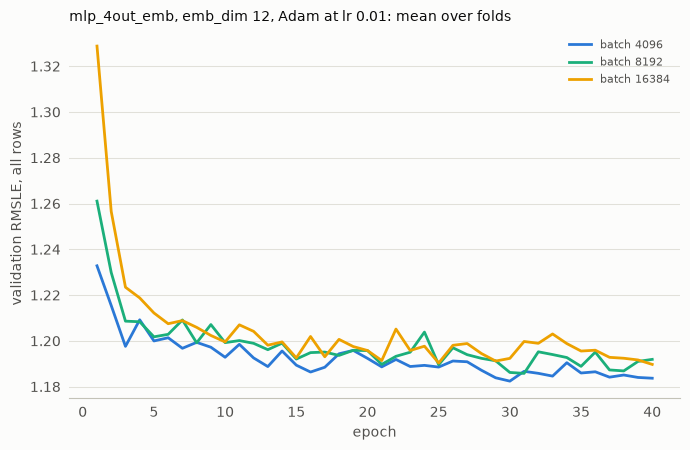

In [33]:
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = dict(zip(SETUPS, ["#2a78d6", "#1baf7a", "#eda100"]))


def style(ax):
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.75)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)


def mean_curve(runs):
    """Validation RMSLE per epoch, mean over folds; a diverged run is shorter."""
    curve = pd.DataFrame(runs.val_curve.tolist()).mean()
    return np.arange(1, len(curve) + 1), curve


FOCUS = 1e-2  # the first plot's rate; opaque in the rate panels, other rates at half opacity
focus = all_results[all_results.lr == FOCUS]
focus_table = focus.groupby("batch_size")[["val", "val_clean", "best_epoch"]].mean()
focus_table["minutes_to_best"] = focus_table.best_epoch * focus_table.index.map(seconds) / 60
display(
    focus_table.round(3)
    .rename(columns={**columns, "val": "average"})
    .rename_axis(columns=f"lr {FOCUS:g}: RMSLE at the best epoch, all rows unless noted")
)

fig, ax = plt.subplots(figsize=(7, 4.6), facecolor=SURFACE)
for batch_size, color in COLORS.items():
    runs = focus[focus.batch_size == batch_size]
    ax.plot(*mean_curve(runs), color=color, lw=2, label=f"batch {batch_size}")
ax.set(xlabel="epoch", ylabel="validation RMSLE, all rows")
ylim = ax.get_ylim()  # the rate panels share it
ax.set_title(
    f"mlp_4out_emb, emb_dim {EMB_DIM}, Adam at lr 0.01: mean over folds",
    loc="left",
    color=INK,
    fontsize=10,
)
style(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=TEXT)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in focus.run_id:
        experiment.client.log_artifact(run_id, FIGURE)

In [ ]:
# clean rows per fold: does the order of batch sizes hold in every fold?
at_best_lr = results[[best_lr[b] == lr for b, lr in zip(results.batch_size, results.lr)]]
for name, runs in {f"lr {FOCUS:g}": focus, "best lr per size": at_best_lr}.items():
    display(
        runs.pivot_table(index="batch_size", columns="fold", values="val_clean")[FOLD_NAMES]
        .round(3)
        .rename_axis(columns=f"{name}: RMSLE at the best epoch, clean rows")
    )

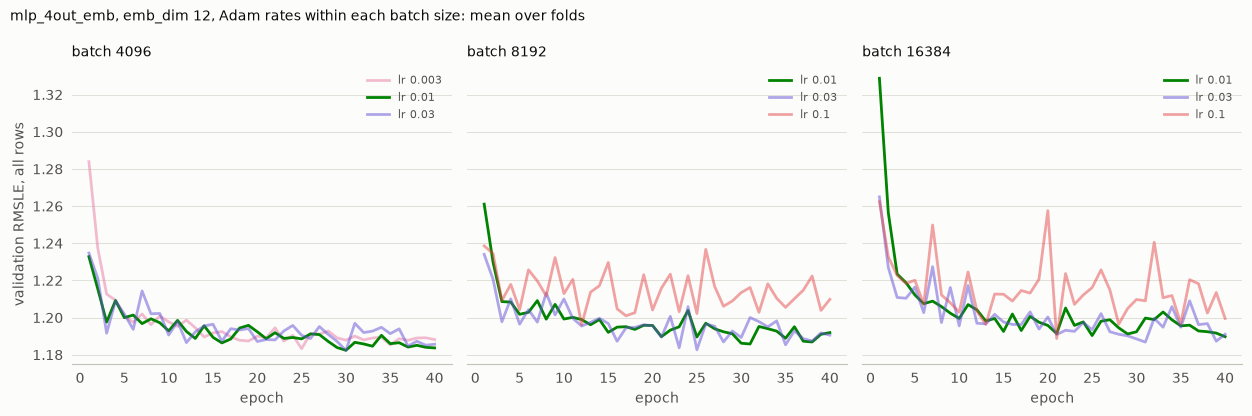

In [34]:
# one colour per rate, the same in every panel
SHADES = {3e-3: "#e87ba4", 1e-2: "#008300", 3e-2: "#6250d6", 1e-1: "#e34948"}
compared = all_results[all_results.lr.isin(SHADES)]

fig, axes = plt.subplots(
    1, len(SETUPS), figsize=(4.2 * len(SETUPS), 4.2), sharey=True, facecolor=SURFACE
)
for ax, batch_size in zip(np.atleast_1d(axes), SETUPS):
    for lr, runs in compared[compared.batch_size == batch_size].groupby("lr"):
        ax.plot(
            *mean_curve(runs),
            color=SHADES[lr],
            lw=2,
            alpha=1 if lr == FOCUS else 0.5,
            label=f"lr {lr:g}",
        )
    ax.set_title(f"batch {batch_size}", loc="left", color=INK, fontsize=10)
    ax.set_xlabel("epoch")
    style(ax)
    ax.legend(frameon=False, fontsize=8, labelcolor=TEXT)
np.atleast_1d(axes)[0].set(ylabel="validation RMSLE, all rows", ylim=ylim)
fig.suptitle(
    f"mlp_4out_emb, emb_dim {EMB_DIM}, Adam rates within each batch size: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
plt.tight_layout()
if FIGURE_RATES:
    fig.savefig(FIGURE_RATES, dpi=150, bbox_inches="tight")
    for run_id in compared.run_id:
        experiment.client.log_artifact(run_id, FIGURE_RATES)